<a href="https://colab.research.google.com/github/jeb29000/AI_Job_Search/blob/main/Pneumonia_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install kaggle

# Downloading the dataset from Kaggle
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia

# Unziping the dataset
!unzip chest-xray-pneumonia.zip

Streaming output truncated to the last 5000 lines.
  inflating: chest_xray/train/NORMAL/IM-0435-0001-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0435-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0437-0001-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0437-0001-0002.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0437-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0438-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0439-0001-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0439-0001-0002.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0439-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0440-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0441-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0442-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0444-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0445-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0446-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0447-0001.jpeg  
  inflating:

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, accuracy_score
import matplotlib.pyplot as plt
import numpy as np
import os
from tensorflow.keras.applications import VGG16


In [ ]:
# train and Validation Directories
train_dir = '/content/chest_xray/chest_xray/train'
val_dir = '/content/chest_xray/chest_xray/val'

# Data Augmentation and Rescaling
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=40,    # Augmentations
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator(rescale=1./255)

# Load data
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)

val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)


Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.


In [ ]:
# Handle Data Imbalance
from sklearn.utils.class_weight import compute_class_weight

# Get class indices from the generator
classes = train_generator.class_indices  # Get the mapping of class names

# Extracting the class names and convert to a NumPy array
class_labels = np.array(list(classes.values()))

y = train_generator.classes  # Get the actual labels

# Computig class weights to handle imbalance
class_weights = compute_class_weight('balanced', classes=class_labels, y=y)

# Converting to dictionary format for model training
class_weights_dict = dict(zip(range(len(class_labels)), class_weights))
print(f'Class weights: {class_weights_dict}')

Class weights: {0: 1.9448173005219984, 1: 0.6730322580645162}


In [ ]:
# Load pre-trained VGG16 without the top layer
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Freeze the layers of VGG16
for layer in base_model.layers:
    layer.trainable = False

# Build the model
model = tf.keras.models.Sequential([
    base_model,  # VGG16 base model
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(512, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(1, activation='sigmoid')  # For binary classification
])

# Compileing the model
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
              loss='binary_crossentropy',
              metrics=['accuracy'])


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
# Enabling mixed precision training
from tensorflow.keras import mixed_precision


# Set up callbacks
checkpoint_filepath = '/tmp/checkpoint.weights.h5'
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=checkpoint_filepath,
        save_weights_only=True,
        monitor='val_accuracy',
        mode='max',
        save_best_only=True
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    ),
    tf.keras.callbacks.TensorBoard(log_dir='./logs')
]

#  setting global policy
mixed_precision.set_global_policy('mixed_float16')

In [ ]:
# Training the model
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=15,
    class_weight=class_weights_dict,  # class weights to handle imbalance
    callbacks=callbacks
)

Epoch 1/15


/usr/local/lib/python3.10/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


163/163 ━━━━━━━━━━━━━━━━━━━━ 137s 713ms/step - accuracy: 0.7868 - loss: 0.4526 - val_accuracy: 0.8125 - val_loss: 0.3120
Epoch 2/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 110s 652ms/step - accuracy: 0.8928 - loss: 0.2563 - val_accuracy: 0.8750 - val_loss: 0.2596
Epoch 3/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 108s 638ms/step - accuracy: 0.9057 - loss: 0.2208 - val_accuracy: 0.8125 - val_loss: 0.4121
Epoch 4/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 107s 631ms/step - accuracy: 0.9158 - loss: 0.2010 - val_accuracy: 0.7500 - val_loss: 0.3372
Epoch 5/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 108s 633ms/step - accuracy: 0.9219 - loss: 0.1923 - val_accuracy: 0.9375 - val_loss: 0.2502
Epoch 6/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 142s 632ms/step - accuracy: 0.9251 - loss: 0.1785 - val_accuracy: 0.8125 - val_loss: 0.4100
Epoch 7/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 108s 636ms/step - accuracy: 0.9399 - loss: 0.1547 - val_accuracy: 0.8125 - val_loss: 0.3856
Epoch 8/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 141s 629ms/step - accuracy: 0.9306 - loss: 0.16

In [ ]:
test_dir = "/content/chest_xray/chest_xray/test"
test_generator = ImageDataGenerator(rescale=1/255)


data_test = test_generator.flow_from_directory(test_dir, target_size=(224,224), batch_size=8, class_mode="binary")

Found 624 images belonging to 2 classes.


In [ ]:
model.evaluate(data_test)

78/78 ━━━━━━━━━━━━━━━━━━━━ 12s 93ms/step - accuracy: 0.8822 - loss: 0.2767


[0.24850916862487793, 0.8910256624221802]

In [ ]:
predictions_test= model.predict(data_test)

78/78 ━━━━━━━━━━━━━━━━━━━━ 5s 59ms/step


In [ ]:
predictions_test

array([[8.51548433e-01],
       [9.99213576e-01],
       [9.84719872e-01],
       [8.38399410e-01],
       [9.98474300e-01],
       [9.89510655e-01],
       [7.29490757e-01],
       [6.37073338e-01],
       [2.97115594e-01],
       [9.94252145e-01],
       [8.25227320e-01],
       [4.92555927e-03],
       [9.63571310e-01],
       [8.53073239e-01],
       [4.50563291e-03],
       [4.59402706e-03],
       [9.43965495e-01],
       [9.92573738e-01],
       [5.70664275e-03],
       [6.46606386e-01],
       [9.97383296e-01],
       [4.46106464e-01],
       [9.56183434e-01],
       [6.78009586e-03],
       [9.34225202e-01],
       [6.72982335e-01],
       [9.17334557e-01],
       [8.83618295e-01],
       [7.94146717e-01],
       [1.21448012e-02],
       [6.29306793e-01],
       [9.81864095e-01],
       [2.43047681e-02],
       [6.37402117e-01],
       [5.09348372e-03],
       [6.34862867e-04],
       [8.89222883e-03],
       [7.80332208e-01],
       [9.90172267e-01],
       [9.92614124e-03],


In [ ]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

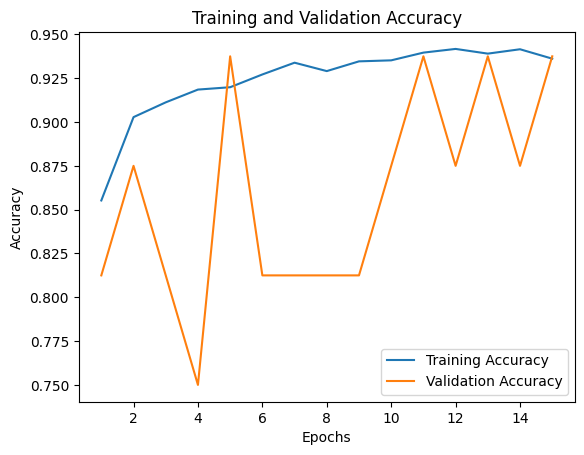

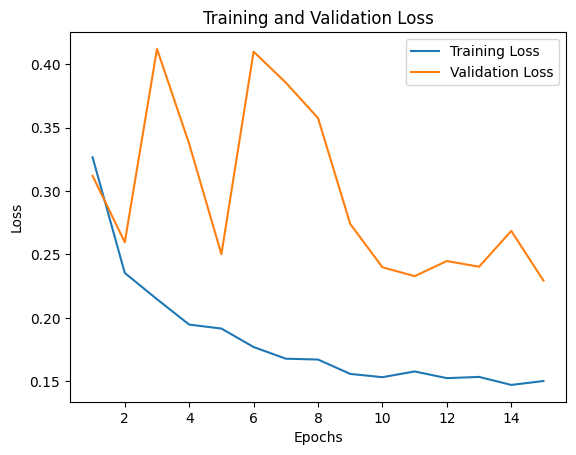

In [ ]:
# Plot accuracy and loss
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(1, len(acc) + 1)

# Plot accuracy
plt.plot(epochs, acc, label='Training Accuracy')
plt.plot(epochs, val_acc, label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Plot loss
plt.plot(epochs, loss, label='Training Loss')
plt.plot(epochs, val_loss, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


78/78 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step


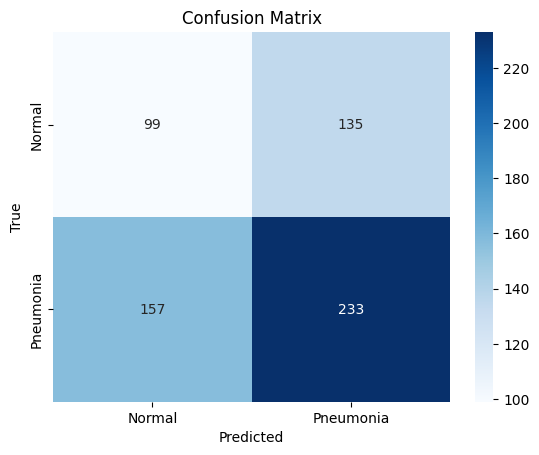

In [ ]:
# Get true labels and predicted labels for the test set
y_true = data_test.classes
y_pred = (model.predict(data_test) > 0.5).astype("int32")

# Create the confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Display the confusion matrix using a heatmap
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Pneumonia'], yticklabels=['Normal', 'Pneumonia'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

In [ ]:

# Evaluate the model on the test set
test_loss, test_acc = model.evaluate(data_test)

# Print the test accuracy
print(f"Test accuracy: {test_acc}")

# Generate a classification report
y_pred_test = (model.predict(data_test) > 0.5).astype("int32")
print(classification_report(data_test.classes, y_pred_test))


78/78 ━━━━━━━━━━━━━━━━━━━━ 6s 73ms/step - accuracy: 0.8891 - loss: 0.2494
Test accuracy: 0.8910256624221802
78/78 ━━━━━━━━━━━━━━━━━━━━ 6s 77ms/step
              precision    recall  f1-score   support

           0       0.33      0.36      0.35       234
           1       0.60      0.56      0.58       390

    accuracy                           0.49       624
   macro avg       0.46      0.46      0.46       624
weighted avg       0.50      0.49      0.49       624



#  Model 2 With SMOTE

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.applications import VGG16
from tensorflow.keras import mixed_precision
from imblearn.over_sampling import SMOTE  # For SMOTE
from sklearn.metrics import classification_report

In [ ]:
# Directories
train_dir = '/content/chest_xray/chest_xray/train'
val_dir = '/content/chest_xray/chest_xray/val'

In [ ]:
# Data Augmentation and Rescaling
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=40,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],  # Add brightness augmentation
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator(rescale=1./255)


In [ ]:
# Load data
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)

val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)


Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.


In [ ]:
# Handle Data Imbalance
classes = train_generator.class_indices
class_labels = np.array(list(classes.values()))
y = train_generator.classes

In [ ]:
# Compute class weights
class_weights = compute_class_weight('balanced', classes=class_labels, y=y)
class_weights_dict = dict(zip(range(len(class_labels)), class_weights))
print(f'Class weights: {class_weights_dict}')


Class weights: {0: 1.9448173005219984, 1: 0.6730322580645162}


In [ ]:
# Load pre-trained VGG16 without the top layer
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


In [ ]:
# Freezing the layers of VGG16
for layer in base_model.layers:
    layer.trainable = False

In [ ]:
# Building the model
model = tf.keras.models.Sequential([
    base_model,
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(512, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(1, activation='sigmoid')  # For binary classification
])

In [ ]:
# Compile the model
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
              loss='binary_crossentropy',
              metrics=['accuracy'])


In [ ]:
# Enabling mixed precision training
mixed_precision.set_global_policy('mixed_float16')

In [ ]:
# Set up for  callbacks
checkpoint_filepath = '/tmp/checkpoint.weights.h5'
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=checkpoint_filepath,
        save_weights_only=True,
        monitor='val_accuracy',
        mode='max',
        save_best_only=True
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    ),
    tf.keras.callbacks.TensorBoard(log_dir='./logs'),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6)  # Learning rate scheduler
]


In [ ]:
#SMOTE
X_train, y_train = next(train_generator)
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train.reshape(-1, 224*224*3), y_train)
X_train_resampled = X_train_resampled.reshape(-1, 224, 224, 3)


In [ ]:
# Training the model
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=20,  # Increase the number of epochs
    class_weight=class_weights_dict,
    callbacks=callbacks
)

Epoch 1/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 165s 814ms/step - accuracy: 0.7961 - loss: 0.4172 - val_accuracy: 0.8125 - val_loss: 0.3547 - learning_rate: 1.0000e-04
Epoch 2/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 118s 686ms/step - accuracy: 0.8913 - loss: 0.2575 - val_accuracy: 0.8125 - val_loss: 0.2610 - learning_rate: 1.0000e-04
Epoch 3/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 144s 699ms/step - accuracy: 0.9010 - loss: 0.2472 - val_accuracy: 0.7500 - val_loss: 0.4102 - learning_rate: 1.0000e-04
Epoch 4/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 141s 704ms/step - accuracy: 0.9154 - loss: 0.2052 - val_accuracy: 0.8750 - val_loss: 0.2854 - learning_rate: 1.0000e-04
Epoch 5/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 120s 706ms/step - accuracy: 0.9217 - loss: 0.1891 - val_accuracy: 0.8750 - val_loss: 0.2370 - learning_rate: 1.0000e-04
Epoch 6/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 146s 733ms/step - accuracy: 0.9188 - loss: 0.1889 - val_accuracy: 0.9375 - val_loss: 0.2700 - learning_rate: 1.0000e-04
Epoch 7/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 

In [ ]:
# test dir
test_dir = "/content/chest_xray/chest_xray/test"
test_generator = ImageDataGenerator(rescale=1./255)

data_test = test_generator.flow_from_directory(test_dir, target_size=(224,224), batch_size=8, class_mode="binary")

Found 624 images belonging to 2 classes.


In [ ]:
# Evaluating the model
loss, accuracy = model.evaluate(data_test)
print(f"Test accuracy: {accuracy}")

/usr/local/lib/python3.10/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


78/78 ━━━━━━━━━━━━━━━━━━━━ 14s 80ms/step - accuracy: 0.9151 - loss: 0.2208
Test accuracy: 0.9070512652397156


In [ ]:
# Predictions for classification report
y_pred = model.predict(data_test)
y_pred_classes = (y_pred > 0.5).astype("int32").flatten()  # Threshold for binary classification
y_true = data_test.classes

78/78 ━━━━━━━━━━━━━━━━━━━━ 7s 78ms/step


In [ ]:
# Printing classification report
print(classification_report(y_true, y_pred_classes, target_names=list(classes.keys())))

              precision    recall  f1-score   support

      NORMAL       0.35      0.34      0.35       234
   PNEUMONIA       0.61      0.63      0.62       390

    accuracy                           0.52       624
   macro avg       0.48      0.48      0.48       624
weighted avg       0.52      0.52      0.52       624



78/78 ━━━━━━━━━━━━━━━━━━━━ 6s 73ms/step


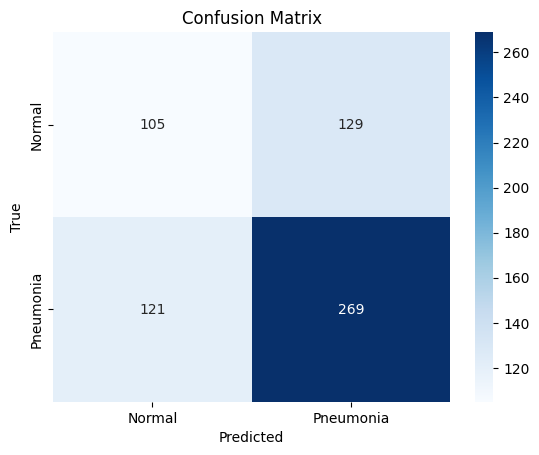

In [ ]:
# prompt: give the code for confusion matrix
!pip install scikit-learn  # Install scikit-learn if not already installed
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix # Importing the confusion_matrix function


# Get true labels and predicted labels for the test set
y_true = data_test.classes
y_pred = (model.predict(data_test) > 0.5).astype("int32")

# Create the confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Display the confusion matrix using a heatmap
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Pneumonia'], yticklabels=['Normal', 'Pneumonia'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

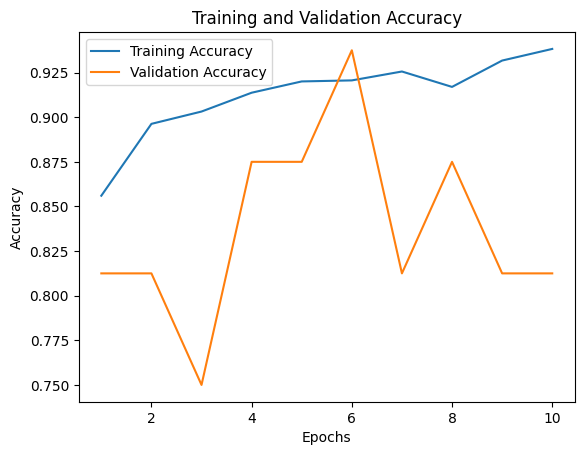

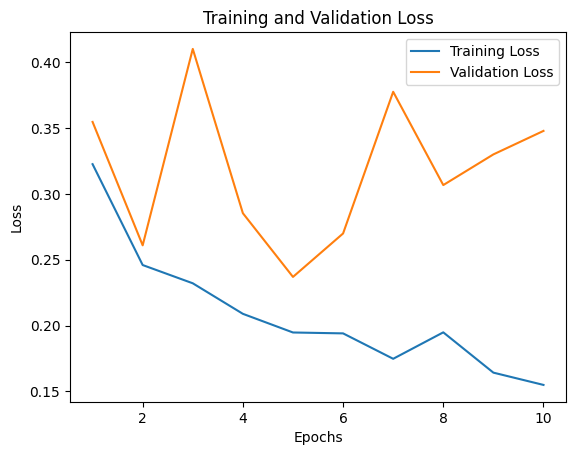

In [ ]:
# Plot accuracy and loss
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(1, len(acc) + 1)

# Plot accuracy
plt.plot(epochs, acc, label='Training Accuracy')
plt.plot(epochs, val_acc, label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Plot loss
plt.plot(epochs, loss, label='Training Loss')
plt.plot(epochs, val_loss, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


# Model 3 with restnet

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet101
from tensorflow.keras.layers import Dense, Flatten, Dropout, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from sklearn.utils.class_weight import compute_class_weight
from imblearn.over_sampling import SMOTE
import numpy as np
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt
from tensorflow.keras import mixed_precision

In [ ]:
# Directories
train_dir = '/content/chest_xray/chest_xray/train'
val_dir = '/content/chest_xray/chest_xray/val'


In [ ]:
# Data Augmentation with elastic transformations and rotations
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=40,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],
    fill_mode='nearest',
    preprocessing_function=lambda x: tf.keras.preprocessing.image.random_rotation(x, rg=40),
)

val_datagen = ImageDataGenerator(rescale=1./255)


In [ ]:
# Load data
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)

val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary'
)


Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.


In [ ]:
# Handle Data Imbalance
classes = train_generator.class_indices
class_labels = np.array(list(classes.values()))
y = train_generator.classes
# Compute class weights
class_weights = compute_class_weight('balanced', classes=class_labels, y=y)
class_weights_dict = dict(zip(range(len(class_labels)), class_weights))
print(f'Class weights: {class_weights_dict}')


Class weights: {0: 1.9448173005219984, 1: 0.6730322580645162}


In [ ]:
# Load pre-trained ResNet101 with the top layer
base_model = ResNet101(weights='imagenet', include_top=False, input_shape=(224, 224, 3))


171446536/171446536 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


In [ ]:
# Add custom layers on top of ResNet101
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(512, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.01))(x)  # Add L2 regularization
x = Dropout(0.5)(x)
predictions = Dense(1, activation='sigmoid')(x)

model = Model(inputs=base_model.input, outputs=predictions)


In [ ]:
# Compile the model
model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='binary_crossentropy',
              metrics=['accuracy'])


In [ ]:
# Enabling mixed precision training
mixed_precision.set_global_policy('mixed_float16')


In [ ]:
# Set up callbacks
checkpoint_filepath = '/tmp/checkpoint.weights.h5'
callbacks = [
    ModelCheckpoint(
        filepath=checkpoint_filepath,
        save_weights_only=True,
        monitor='val_accuracy',
        mode='max',
        save_best_only=True
    ),
    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6)
]


In [ ]:
# Training the model with SMOTE
X_train, y_train = next(train_generator)

# Count the number of samples in the minority class
n_minority_samples = len(y_train[y_train == 1])

# Dynamically adjust k_neighbors, ensuring it's less than the number of minority samples
k_neighbors = min(5, n_minority_samples - 1) if n_minority_samples > 1 else 1

# Instantiate SMOTE with the adjusted k_neighbors
smote = SMOTE(random_state=42, k_neighbors=k_neighbors)

# If the minority class has more than one sample, set k_neighbors to the minimum between 5 and the number of samples minus 1.
# If there's only one sample or none, set k_neighbors to 1 to avoid the error.

X_train_resampled, y_train_resampled = smote.fit_resample(X_train.reshape(-1, 224*224*3), y_train)
X_train_resampled = X_train_resampled.reshape(-1, 224, 224, 3)


history = model.fit(
    X_train_resampled, y_train_resampled,
    validation_data=val_generator,
    epochs=10,  # Increase the number of epochs
    class_weight=class_weights_dict,
    callbacks=callbacks
)

Epoch 1/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 63s/step - accuracy: 0.5482 - loss: 9.6167   

/usr/local/lib/python3.10/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


2/2 ━━━━━━━━━━━━━━━━━━━━ 204s 75s/step - accuracy: 0.5539 - loss: 9.5627 - val_accuracy: 0.5000 - val_loss: 8.9335 - learning_rate: 1.0000e-04
Epoch 2/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 14s 488ms/step - accuracy: 0.8963 - loss: 8.3773 - val_accuracy: 0.5000 - val_loss: 8.9589 - learning_rate: 1.0000e-04
Epoch 3/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 454ms/step - accuracy: 0.9606 - loss: 8.2663 - val_accuracy: 0.5000 - val_loss: 8.9810 - learning_rate: 1.0000e-04
Epoch 4/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 441ms/step - accuracy: 1.0000 - loss: 8.1421 - val_accuracy: 0.5000 - val_loss: 9.0113 - learning_rate: 1.0000e-04
Epoch 5/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 438ms/step - accuracy: 1.0000 - loss: 8.0900 - val_accuracy: 0.5000 - val_loss: 8.9999 - learning_rate: 2.0000e-05
Epoch 6/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 435ms/step - accuracy: 1.0000 - loss: 8.0717 - val_accuracy: 0.5000 - val_loss: 8.9854 - learning_rate: 2.0000e-05


In [ ]:
# Evaluate the model on the test set
test_dir = "/content/chest_xray/chest_xray/test"
test_generator = ImageDataGenerator(rescale=1./255)
data_test = test_generator.flow_from_directory(test_dir, target_size=(224, 224), batch_size=8, class_mode="binary")

loss, accuracy = model.evaluate(data_test)
print(f"Test accuracy: {accuracy}")


Found 624 images belonging to 2 classes.
78/78 ━━━━━━━━━━━━━━━━━━━━ 11s 92ms/step - accuracy: 0.3734 - loss: 9.0352
Test accuracy: 0.375


In [ ]:
# Predictions for classification report
y_pred = model.predict(data_test)
y_pred_classes = (y_pred > 0.5).astype("int32").flatten()  # Threshold for binary classification
y_true = data_test.classes

# Printing classification report
print(classification_report(y_true, y_pred_classes, target_names=list(classes.keys())))

78/78 ━━━━━━━━━━━━━━━━━━━━ 15s 73ms/step
              precision    recall  f1-score   support

      NORMAL       0.38      1.00      0.55       234
   PNEUMONIA       0.00      0.00      0.00       390

    accuracy                           0.38       624
   macro avg       0.19      0.50      0.27       624
weighted avg       0.14      0.38      0.20       624



/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
